Engineering Dataset:
   mechain_data   vibration  tempature  pressure  operating-hours    status
0          m101        2.1       72.5     101.2             1200    normal
1          m102        4.5       85.3     105.6             1500   warning
2          m103        7.8       68.7      99.8              900    normal
3          m104        5.2       91.2     110.3             1800  critical
4          m105        2.8       76.5     102.5             1100    normal
5          m106        4.1       88.5     108.7             1650   warning
6          m107        2.0       70.7     100.1              950    normal
7          m108        5.8       94.6     112.4             2000  critical
8          m109        3.2       79.3     103.6             1300    normal
9          m110        4.0       86.7     107.9             1550   warning


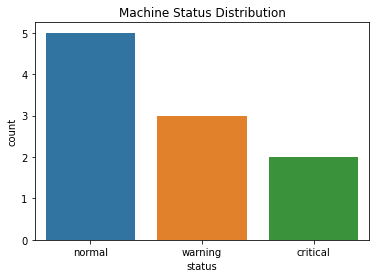

KeyError: "None of [Index(['Temperature', 'Pressure', 'Vibration', 'Operating_Hours'], dtype='object')] are in the [columns]"

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
df = pd.read_csv("week9 dataset.csv")
print("Engineering Dataset:\n", df)
df = df.drop_duplicates()
df = df.dropna(subset=["status"])
sns.countplot(data=df, x="status")
plt.title("Machine Status Distribution")
plt.show()
X = df[["tempature", "pressure", "vibration", "operating_Hours"]]
y = df["status"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
model = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\nActual Status:", y_test.values)
print("Predicted Status:", y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(
    y_test, y_pred, zero_division=0
))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()
new_machine = pd.DataFrame({
    "Temperature": [90.0],
    "Pressure": [109.0],
    "Vibration": [5.0],
    "Operating_Hours": [1750]
})
print("\nNew Machine Status:", model.predict(new_machine)[0])
pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).to_csv("prediction_results.csv", index=False)
print("\nResults saved successfully!")